# 03 · Siamese Network for Person Re-Identification

The detector tells us *where* people are. To keep the *same ID* on the same person, the tracker also needs to answer: **"is this the same person I saw before?"**

That is what the Siamese network does:
* One network with **shared weights** turns a person crop into a 128-number embedding
* We train it with **triplet loss**: an anchor crop should be closer to another crop of the same person (positive) than to a crop of anyone else (negative), by at least a margin

$$L = \max\big(0,\ \|f(a) - f(p)\|_2 - \|f(a) - f(n)\|_2 + \alpha\big)$$

Because it learns a *distance* rather than a fixed list of identities, it works on people it has never seen (everyone in the test video) without re-training. This is the key argument from the slides.

**Our choices**
* Backbone: ImageNet-pretrained **ResNet-18** with a 128-d embedding head. A 3-layer CNN trained from scratch is too weak to tell apart two people in similar dark jackets.
* **Batch-hard** triplet mining (Hermans et al., 2017): each batch has 16 people × 4 crops; for every anchor we use its hardest positive and hardest negative.
* Augmentation: flip, random crop, colour jitter, **random erasing** (simulates someone walking in front)
* Evaluation on MOT16-09 people, who are **never used in training**

Runtime: **T4 GPU**, about 15–20 minutes.

In [1]:
# ---- Setup (identical in every notebook) -----------------------------------
# The ONLY line you may need to change: where the project folder sits on your Drive.
# If a teammate shared the folder with you, right-click it in Drive ->
# "Organize" -> "Add shortcut" -> My Drive, and this path will work unchanged.
PROJECT_DIR = "/content/drive/MyDrive/DL_Project_MOT"

from google.colab import drive
drive.mount("/content/drive")

import os, sys
assert os.path.isdir(os.path.join(PROJECT_DIR, "src")), (
    f"Can't find {PROJECT_DIR}/src. Upload the project folder to Drive first (see README).")
sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))

import config
paths = config.get_paths(PROJECT_DIR)

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (switch the runtime to T4 GPU!)")

Mounted at /content/drive
Device: Tesla T4


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mot_data import prepare_reid_crops
from reid import (ReIDFolder, PKSampler, SiameseReID, ImageNetBaseline, train_transform, eval_transform,
                  train_reid, embed_dataset, evaluate_reid, MEAN, STD)

prepare_reid_crops(paths)
train_ds = ReIDFolder(paths.reid_train, train_transform(), min_images=4)
val_ds = ReIDFolder(paths.reid_val, eval_transform(), max_per_id=40)   # cap per person keeps eval balanced
print(f"Train: {train_ds.num_ids} people, {len(train_ds)} crops")
print(f"Val (unseen people, MOT16-09): {val_ds.num_ids} people, {len(val_ds)} crops")

Unzipping Re-ID crops ...
Train: 362 people, 20146 crops
Val (unseen people, MOT16-09): 24 people, 747 crops


## 1. What a training batch looks like

Each row is one person (4 crops, augmented). Triplet loss needs several crops of the same person in every batch, which is why we use a P×K sampler instead of plain shuffling.

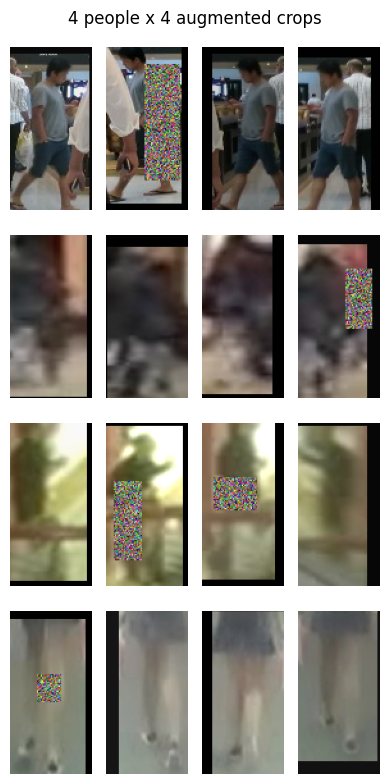

In [3]:
P, K = 16, 4
sampler = PKSampler(train_ds, P=P, K=K, batches_per_epoch=200)
train_loader = torch.utils.data.DataLoader(train_ds, batch_sampler=sampler, num_workers=2, pin_memory=True)

imgs, labels = next(iter(train_loader))
mean, std = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(4, K, figsize=(4, 8))
for r in range(4):
    for c in range(K):
        axes[r, c].imshow((imgs[r * K + c] * std + mean).clamp(0, 1).permute(1, 2, 0)); axes[r, c].axis("off")
plt.suptitle("4 people x 4 augmented crops"); plt.tight_layout()
plt.savefig(f"{paths.figures}/reid_batch_example.jpg", dpi=120); plt.show()

## 2. Baseline: ImageNet features with no Re-ID training

How good is a ResNet-18 that has only seen ImageNet? This tells us how much our triplet training actually adds.

**Metrics** (all on unseen MOT16-09 people):
* **Rank-1**: for a query crop, is the closest other crop the same person? (crops of the same person within 15 frames are excluded, otherwise it is too easy)
* **mAP**: the same idea, averaged over all correct matches
* **AUC / accuracy**: for random pairs, how well does the distance separate "same" from "different"? This is exactly the decision the tracker makes.

In [4]:
val_fn = lambda m: evaluate_reid(*embed_dataset(m, val_ds, device))

baseline = ImageNetBaseline().to(device).eval()
base_res = val_fn(baseline)
print(f"ImageNet ResNet-18 (no Re-ID training): rank-1 {base_res['rank1']:.3f} | mAP {base_res['mAP']:.3f} "
      f"| AUC {base_res['AUC']:.3f} | pair accuracy {base_res['best_acc']:.3f}")
del baseline

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 181MB/s]


ImageNet ResNet-18 (no Re-ID training): rank-1 0.812 | mAP 0.490 | AUC 0.860 | pair accuracy 0.789


## 3. Train the Siamese network with triplet loss

* Adam, lr 3e-4, weight decay 5e-4, cosine schedule, 25 epochs × 200 batches
* Margin α = 0.3 (embeddings are L2-normalised, so distances lie between 0 and 2)
* "Active triplets" = share of anchors still violating the margin. It should fall as the model learns.

In [5]:
EPOCHS = 25
torch.manual_seed(0)
model = SiameseReID(emb_dim=128, pretrained=True).to(device)
history = train_reid(model, train_loader, device, epochs=EPOCHS, ckpt_path=paths.reid_ckpt,
                     lr=3e-4, margin=0.3, val_fn=val_fn, val_every=5)

Epoch  1 | triplet loss 0.3059 | active triplets 87% | 19s
Epoch  2 | triplet loss 0.1566 | active triplets 60% | 19s
Epoch  3 | triplet loss 0.1258 | active triplets 52% | 18s
Epoch  4 | triplet loss 0.1062 | active triplets 47% | 18s
Epoch  5 | triplet loss 0.0962 | active triplets 43% | 19s | val rank-1 0.870 mAP 0.642 AUC 0.927
Epoch  6 | triplet loss 0.0877 | active triplets 40% | 18s
Epoch  7 | triplet loss 0.0786 | active triplets 37% | 18s
Epoch  8 | triplet loss 0.0790 | active triplets 37% | 19s
Epoch  9 | triplet loss 0.0652 | active triplets 33% | 18s
Epoch 10 | triplet loss 0.0676 | active triplets 33% | 18s | val rank-1 0.885 mAP 0.676 AUC 0.929
Epoch 11 | triplet loss 0.0569 | active triplets 30% | 18s
Epoch 12 | triplet loss 0.0545 | active triplets 28% | 19s
Epoch 13 | triplet loss 0.0506 | active triplets 27% | 19s
Epoch 14 | triplet loss 0.0456 | active triplets 24% | 18s
Epoch 15 | triplet loss 0.0373 | active triplets 22% | 18s | val rank-1 0.876 mAP 0.703 AUC 0.93

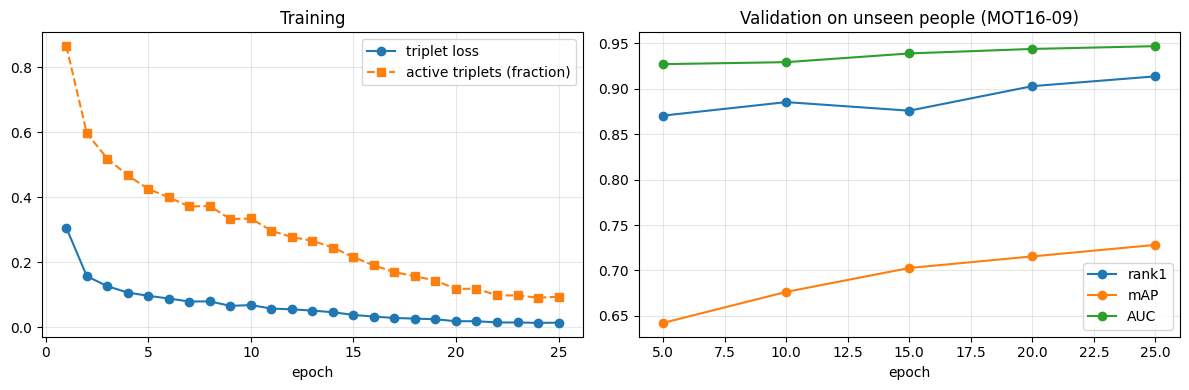

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["epoch"], history["loss"], "o-", label="triplet loss")
axes[0].plot(history["epoch"], history["active"], "s--", label="active triplets (fraction)")
axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=.3); axes[0].set_title("Training")
ep = [e for e, _ in history["val"]]
for key in ["rank1", "mAP", "AUC"]:
    axes[1].plot(ep, [r[key] for _, r in history["val"]], "o-", label=key)
axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=.3)
axes[1].set_title("Validation on unseen people (MOT16-09)")
plt.tight_layout(); plt.savefig(f"{paths.figures}/reid_training.png", dpi=150); plt.show()

## 4. Results

In [7]:
model.eval()
final = val_fn(model)
table = pd.DataFrame([
    {"Model": "ResNet-18, ImageNet only (no Re-ID training)", "Rank-1": base_res["rank1"],
     "mAP": base_res["mAP"], "AUC": base_res["AUC"], "Pair accuracy": base_res["best_acc"]},
    {"Model": "Siamese ResNet-18 + triplet loss (ours)", "Rank-1": final["rank1"],
     "mAP": final["mAP"], "AUC": final["AUC"], "Pair accuracy": final["best_acc"]},
]).round(3)
table.to_csv(f"{paths.tables}/reid_results.csv", index=False)
table

,Model,Rank-1,mAP,AUC,Pair accuracy
0,"ResNet-18, ImageNet only (no Re-ID training)",0.812,0.490,0.860,0.789
1,Siamese ResNet-18 + triplet loss (ours),0.914,0.728,0.947,0.895


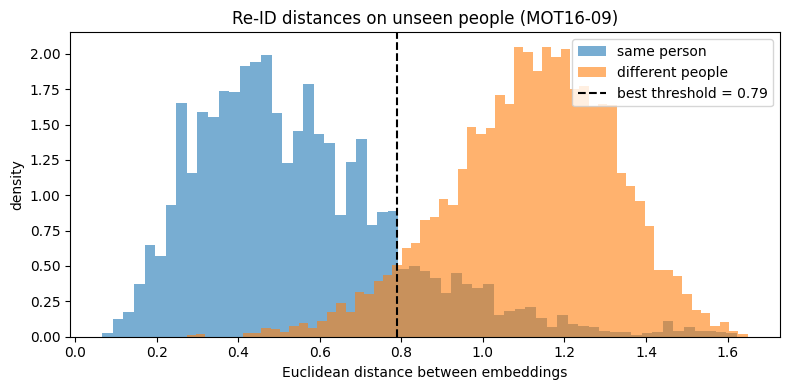

Suggested appearance threshold for the tracker (cosine): 0.312


In [8]:
# Distance histogram: the tracker needs a threshold between these two humps
plt.figure(figsize=(8, 4))
plt.hist(final["pos_dist"], bins=60, alpha=.6, density=True, label="same person")
plt.hist(final["neg_dist"], bins=60, alpha=.6, density=True, label="different people")
plt.axvline(final["best_threshold"], color="k", ls="--", label=f"best threshold = {final['best_threshold']:.2f}")
plt.xlabel("Euclidean distance between embeddings"); plt.ylabel("density"); plt.legend()
plt.title("Re-ID distances on unseen people (MOT16-09)")
plt.tight_layout(); plt.savefig(f"{paths.figures}/reid_distance_hist.png", dpi=150); plt.show()

# The tracker works with cosine distance. For unit vectors: cosine distance = euclidean^2 / 2
cos_thresh = final["best_threshold"] ** 2 / 2
summary = {k: float(final[k]) for k in ["rank1", "mAP", "AUC", "best_acc", "best_threshold"]}
summary["tracker_app_thresh_cosine"] = round(float(cos_thresh), 3)
json.dump(summary, open(f"{paths.tables}/reid_summary.json", "w"), indent=2)
print(f"Suggested appearance threshold for the tracker (cosine): {cos_thresh:.3f}")

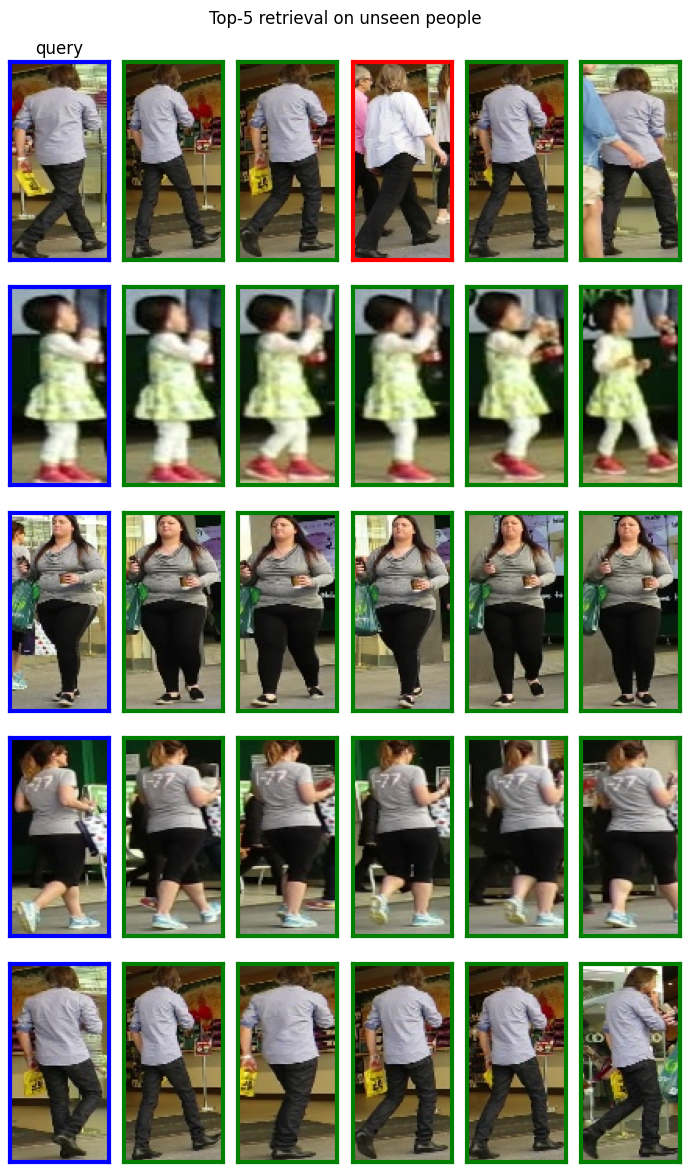

In [9]:
# Retrieval examples: query on the left, 5 closest crops from other moments (green = same person)
feats, labels, frames = embed_dataset(model, val_ds, device)
dist = np.sqrt(np.clip(2 - 2 * feats @ feats.T, 0, None))
rng = np.random.default_rng(3)
queries = rng.choice(len(val_ds), 5, replace=False)
fig, axes = plt.subplots(5, 6, figsize=(7, 12))
for r, q in enumerate(queries):
    ok = ~((labels == labels[q]) & (np.abs(frames - frames[q]) < 15))
    cand = np.where(ok)[0]
    top = cand[np.argsort(dist[q, cand])[:5]]
    for c, idx in enumerate([q, *top]):
        img = (val_ds[idx][0] * std + mean).clamp(0, 1).permute(1, 2, 0)
        axes[r, c].imshow(img); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        color = "blue" if c == 0 else ("green" if labels[idx] == labels[q] else "red")
        for s in axes[r, c].spines.values():
            s.set_color(color); s.set_linewidth(3)
axes[0, 0].set_title("query"); plt.suptitle("Top-5 retrieval on unseen people")
plt.tight_layout(); plt.savefig(f"{paths.figures}/reid_retrieval.jpg", dpi=120); plt.show()

## Done ✅

* Model: `weights/reid_resnet18_triplet.pth` (Drive only)
* `results/tables/reid_results.csv`, `reid_summary.json` (notebook 04 reads the threshold from here)
* Figures: `reid_batch_example.jpg`, `reid_training.png`, `reid_distance_hist.png`, `reid_retrieval.jpg`

**For the report:** the gap between the two rows of the table is what triplet training buys us. The histogram explains how the tracker decides "same person or not".